# Portuguese Bank Marketing Prediction

## Project Overview

This project analyzes direct marketing campaign data from a Portuguese bank. The goal is to predict whether a customer subscribed to a term deposit (`y` = yes or no), then use the analysis to suggest ways to prioritize future outreach.

The supplied CSV contains 41,188 records and 21 columns. After removing 12 exact duplicate rows, the analysis uses 41,176 records. About 11.27% of the records have a “yes” outcome, so the target is imbalanced.

## Project Objectives

- Explore the data and summarize patterns in subscription outcomes.
- Compare logistic regression, a decision tree, and a random forest.
- Evaluate models with metrics that account for the imbalanced target.
- Recommend practical outreach approaches based on the findings.
- Document data challenges and limitations.

## Modeling Scope

The `duration` feature is excluded from the predictive models because call duration is only known after the call. The model should use information available before outreach.

## Dataset Source

[Portuguese Bank Marketing dataset ZIP](https://d3ilbtxij3aepc.cloudfront.net/projects/CDS-Capstone-Projects/PRCP-1000-ProtugeseBank.zip)

Dataset file used: `Data/bank-additional/bank-additional-full.csv`

## Data Loading, Cleaning, and Exploratory Analysis


In [1]:
from pathlib import Path
import pandas as pd

data_candidates = [
    Path("bank-additional-full.csv"),
    Path("Data") / "bank-additional" / "bank-additional-full.csv",
    Path("bank-additional") / "bank-additional-full.csv",
]
file_path = next((path for path in data_candidates if path.exists()), None)
if file_path is None:
    raise FileNotFoundError(
        "Download and extract the dataset, then place bank-additional-full.csv "
        "beside this notebook or under Data/bank-additional/."
    )
df = pd.read_csv(file_path, sep=";")

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [2]:
print(df["y"].value_counts())
print((df["y"].value_counts(normalize=True) * 100).round(2))

y
no     36548
yes     4640
Name: count, dtype: int64
y
no     88.73
yes    11.27
Name: proportion, dtype: float64


In [3]:
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing values: 0
Duplicate rows: 12


In [4]:
duplicate_rows = df[df.duplicated(keep=False)]

print("Rows involved in duplicates:", len(duplicate_rows))
print("Target values among them:")
print(duplicate_rows["y"].value_counts())

display(duplicate_rows.head(10))

Rows involved in duplicates: 24
Target values among them:
y
no     22
yes     2
Name: count, dtype: int64


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
1265,39,blue-collar,married,basic.6y,no,no,no,telephone,may,thu,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.855,5191.0,no
1266,39,blue-collar,married,basic.6y,no,no,no,telephone,may,thu,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.855,5191.0,no
12260,36,retired,married,unknown,no,no,no,telephone,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.966,5228.1,no
12261,36,retired,married,unknown,no,no,no,telephone,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.966,5228.1,no
14155,27,technician,single,professional.course,no,no,no,cellular,jul,mon,...,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
14234,27,technician,single,professional.course,no,no,no,cellular,jul,mon,...,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
16819,47,technician,divorced,high.school,no,yes,no,cellular,jul,thu,...,3,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
16956,47,technician,divorced,high.school,no,yes,no,cellular,jul,thu,...,3,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
18464,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,no
18465,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,no


In [5]:
print("Shape before:", df.shape)

df = df.drop_duplicates().reset_index(drop=True)

print("Shape after:", df.shape)
print("Duplicates remaining:", df.duplicated().sum())

Shape before: (41188, 21)
Shape after: (41176, 21)
Duplicates remaining: 0


In [6]:
df.info()

unknown_counts = (df == "unknown").sum()
print("\nColumns containing 'unknown':")
print(unknown_counts[unknown_counts > 0].sort_values(ascending=False))

<class 'pandas.DataFrame'>
RangeIndex: 41176 entries, 0 to 41175
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41176 non-null  int64  
 1   job             41176 non-null  str    
 2   marital         41176 non-null  str    
 3   education       41176 non-null  str    
 4   default         41176 non-null  str    
 5   housing         41176 non-null  str    
 6   loan            41176 non-null  str    
 7   contact         41176 non-null  str    
 8   month           41176 non-null  str    
 9   day_of_week     41176 non-null  str    
 10  duration        41176 non-null  int64  
 11  campaign        41176 non-null  int64  
 12  pdays           41176 non-null  int64  
 13  previous        41176 non-null  int64  
 14  poutcome        41176 non-null  str    
 15  emp.var.rate    41176 non-null  float64
 16  cons.price.idx  41176 non-null  float64
 17  cons.conf.idx   41176 non-null  float64
 1

In [7]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,41176.0,40.02,10.42,17.00,32.00,38.00,47.00,98.00
duration,41176.0,258.32,259.31,0.00,102.00,180.00,319.00,4918.00
campaign,41176.0,2.57,2.77,1.00,1.00,2.00,3.00,56.00
pdays,41176.0,962.46,186.94,0.00,999.00,999.00,999.00,999.00
previous,41176.0,0.17,0.49,0.00,0.00,0.00,0.00,7.00
emp.var.rate,41176.0,0.08,1.57,-3.40,-1.80,1.10,1.40,1.40
cons.price.idx,41176.0,93.58,0.58,92.20,93.08,93.75,93.99,94.77
cons.conf.idx,41176.0,-40.50,4.63,-50.80,-42.70,-41.80,-36.40,-26.90
euribor3m,41176.0,3.62,1.73,0.63,1.34,4.86,4.96,5.04
nr.employed,41176.0,5167.03,72.25,4963.60,5099.10,5191.00,5228.10,5228.10


In [8]:
for col in ["contact", "month", "poutcome", "previous"]:
    yes_rate = (
        df.groupby(col, observed=False)["y"]
          .apply(lambda values: (values == "yes").mean() * 100)
          .sort_values(ascending=False)
          .round(2)
    )
    print(f"\nSubscription rate by {col} (%):")
    print(yes_rate)


Subscription rate by contact (%):
contact
cellular     14.74
telephone     5.23
Name: y, dtype: float64

Subscription rate by month (%):
month
mar    50.55
dec    48.90
sep    44.91
oct    43.93
apr    20.49
aug    10.61
jun    10.51
nov    10.15
jul     9.04
may     6.44
Name: y, dtype: float64

Subscription rate by poutcome (%):
poutcome
success        65.11
failure        14.23
nonexistent     8.83
Name: y, dtype: float64

Subscription rate by previous (%):
previous
5    72.22
6    60.00
3    59.26
4    54.29
2    46.42
1    21.20
0     8.83
7     0.00
Name: y, dtype: float64


In [9]:
for col in ["month", "previous"]:
    summary = df.groupby(col, observed=False).agg(
        customers=("y", "size"),
        subscriptions=("y", lambda values: (values == "yes").sum())
    )
    summary["subscription_rate_pct"] = (
        summary["subscriptions"] / summary["customers"] * 100
    ).round(2)

    print(f"\n{col}:")
    display(summary.sort_values("subscription_rate_pct", ascending=False))


month:


,customers,subscriptions,subscription_rate_pct
month,,,
mar,546,276,50.55
dec,182,89,48.90
sep,570,256,44.91
oct,717,315,43.93
apr,2631,539,20.49
aug,6176,655,10.61
jun,5318,559,10.51
nov,4100,416,10.15
jul,7169,648,9.04



previous:


,customers,subscriptions,subscription_rate_pct
previous,,,
5,18,13,72.22
6,5,3,60.00
3,216,128,59.26
4,70,38,54.29
2,754,350,46.42
1,4561,967,21.20
0,35551,3140,8.83
7,1,0,0.00


In [10]:
df["prior_contact_status"] = df["pdays"].apply(
    lambda days: "Not previously contacted" if days == 999
    else "Previously contacted"
)

prior_summary = df.groupby("prior_contact_status").agg(
    customers=("y", "size"),
    subscriptions=("y", lambda values: (values == "yes").sum())
)
prior_summary["subscription_rate_pct"] = (
    prior_summary["subscriptions"] / prior_summary["customers"] * 100
).round(2)

display(prior_summary)

,customers,subscriptions,subscription_rate_pct
prior_contact_status,,,
Not previously contacted,39661,3672,9.26
Previously contacted,1515,967,63.83


In [11]:
df["age_group"] = pd.cut(
    df["age"],
    bins=[0, 25, 35, 45, 55, 65, 100],
    labels=["Under 26", "26–35", "36–45", "46–55", "56–65", "Over 65"]
)

age_summary = df.groupby("age_group", observed=False).agg(
    customers=("y", "size"),
    subscriptions=("y", lambda values: (values == "yes").sum())
)
age_summary["subscription_rate_pct"] = (
    age_summary["subscriptions"] / age_summary["customers"] * 100
).round(2)

display(age_summary)

,customers,subscriptions,subscription_rate_pct
age_group,,,
Under 26,1665,349,20.96
26–35,14844,1740,11.72
36–45,12839,1092,8.51
46–55,8247,717,8.69
56–65,2963,451,15.22
Over 65,618,290,46.93


In [13]:
df["campaign_group"] = df["campaign"].clip(upper=5)
df["campaign_group"] = df["campaign_group"].replace(5, "5+")

campaign_summary = df.groupby("campaign_group", observed=False).agg(
    customers=("y", "size"),
    subscriptions=("y", lambda values: (values == "yes").sum())
)
campaign_summary["subscription_rate_pct"] = (
    campaign_summary["subscriptions"] / campaign_summary["customers"] * 100
).round(2)

display(campaign_summary)

,customers,subscriptions,subscription_rate_pct
campaign_group,,,
1,17634,2299,13.04
2,10568,1211,11.46
3,5340,574,10.75
4,2650,249,9.40
5+,4984,306,6.14


## Predictive Modeling and Evaluation


In [14]:
from sklearn.model_selection import train_test_split

y = df["y"].map({"no": 0, "yes": 1})

columns_to_exclude = [
    "y", "duration",
    "prior_contact_status", "age_group", "campaign_group"
]
X = df.drop(columns=columns_to_exclude)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
print("\nSubscription rate in training data:")
print((y_train.mean() * 100).round(2), "%")
print("Subscription rate in test data:")
print((y_test.mean() * 100).round(2), "%")

Training rows: 32940
Test rows: 8236

Subscription rate in training data:
11.27 %
Subscription rate in test data:
11.27 %


In [15]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix
)

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

baseline_pred = baseline.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, baseline_pred), 4))
print("Precision:", round(precision_score(y_test, baseline_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, baseline_pred, zero_division=0), 4))
print("F1 score:", round(f1_score(y_test, baseline_pred, zero_division=0), 4))
print("\nConfusion matrix:")
print(confusion_matrix(y_test, baseline_pred))

Accuracy: 0.8873
Precision: 0.0
Recall: 0.0
F1 score: 0.0

Confusion matrix:
[[7308    0]
 [ 928    0]]


In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

numeric_features = X_train.select_dtypes(include="number").columns
categorical_features = X_train.select_dtypes(exclude="number").columns

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced"
    ))
])

logistic_model.fit(X_train, y_train)
logistic_pred = logistic_model.predict(X_test)

print("Confusion matrix:")
print(confusion_matrix(y_test, logistic_pred))
print("\nClassification report:")
print(classification_report(
    y_test, logistic_pred,
    target_names=["no subscription", "subscription"],
    digits=3,
    zero_division=0
))

Confusion matrix:
[[6239 1069]
 [ 329  599]]

Classification report:
                 precision    recall  f1-score   support

no subscription      0.950     0.854     0.899      7308
   subscription      0.359     0.645     0.461       928

       accuracy                          0.830      8236
      macro avg      0.655     0.750     0.680      8236
   weighted avg      0.883     0.830     0.850      8236



In [17]:
from sklearn.tree import DecisionTreeClassifier

tree_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=6,
        min_samples_leaf=50,
        class_weight="balanced",
        random_state=42
    ))
])

tree_model.fit(X_train, y_train)
tree_pred = tree_model.predict(X_test)

print("Confusion matrix:")
print(confusion_matrix(y_test, tree_pred))
print("\nClassification report:")
print(classification_report(
    y_test, tree_pred,
    target_names=["no subscription", "subscription"],
    digits=3,
    zero_division=0
))

Confusion matrix:
[[6391  917]
 [ 339  589]]

Classification report:
                 precision    recall  f1-score   support

no subscription      0.950     0.875     0.911      7308
   subscription      0.391     0.635     0.484       928

       accuracy                          0.847      8236
      macro avg      0.670     0.755     0.697      8236
   weighted avg      0.887     0.847     0.862      8236



In [18]:
from sklearn.ensemble import RandomForestClassifier

forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=12,
        min_samples_leaf=10,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])

forest_model.fit(X_train, y_train)
forest_pred = forest_model.predict(X_test)

print("Confusion matrix:")
print(confusion_matrix(y_test, forest_pred))
print("\nClassification report:")
print(classification_report(
    y_test, forest_pred,
    target_names=["no subscription", "subscription"],
    digits=3,
    zero_division=0
))

Confusion matrix:
[[6492  816]
 [ 338  590]]

Classification report:
                 precision    recall  f1-score   support

no subscription      0.951     0.888     0.918      7308
   subscription      0.420     0.636     0.506       928

       accuracy                          0.860      8236
      macro avg      0.685     0.762     0.712      8236
   weighted avg      0.891     0.860     0.872      8236



In [19]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score
)

models = {
    "Logistic regression": logistic_model,
    "Decision tree": tree_model,
    "Random forest": forest_model
}

rows = []

for name, model in models.items():
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    rows.append({
        "model": name,
        "accuracy": accuracy_score(y_test, predictions),
        "precision_yes": precision_score(y_test, predictions, zero_division=0),
        "recall_yes": recall_score(y_test, predictions, zero_division=0),
        "f1_yes": f1_score(y_test, predictions, zero_division=0),
        "roc_auc": roc_auc_score(y_test, probabilities),
        "average_precision": average_precision_score(y_test, probabilities)
    })

comparison = pd.DataFrame(rows).set_index("model").round(3)
display(comparison.sort_values("f1_yes", ascending=False))

,accuracy,precision_yes,recall_yes,f1_yes,roc_auc,average_precision
model,,,,,,
Random forest,0.860,0.420,0.636,0.506,0.813,0.487
Decision tree,0.847,0.391,0.635,0.484,0.801,0.458
Logistic regression,0.830,0.359,0.645,0.461,0.800,0.446


In [20]:
from sklearn.metrics import precision_score, recall_score, f1_score

forest_probabilities = forest_model.predict_proba(X_test)[:, 1]

threshold_rows = []

for threshold in [0.30, 0.40, 0.50, 0.60, 0.70]:
    predictions = (forest_probabilities >= threshold).astype(int)

    threshold_rows.append({
        "threshold": threshold,
        "customers_flagged": int(predictions.sum()),
        "precision_yes": precision_score(y_test, predictions, zero_division=0),
        "recall_yes": recall_score(y_test, predictions, zero_division=0),
        "f1_yes": f1_score(y_test, predictions, zero_division=0)
    })

threshold_comparison = pd.DataFrame(threshold_rows).set_index("threshold").round(3)
display(threshold_comparison)

,customers_flagged,precision_yes,recall_yes,f1_yes
threshold,,,,
0.3,4094,0.191,0.841,0.311
0.4,2036,0.321,0.704,0.441
0.5,1406,0.420,0.636,0.506
0.6,1217,0.464,0.609,0.527
0.7,1016,0.497,0.544,0.520


In [21]:
from sklearn.inspection import permutation_importance

X_importance = X_test.sample(n=2000, random_state=42)
y_importance = y_test.loc[X_importance.index]

importance = permutation_importance(
    forest_model,
    X_importance,
    y_importance,
    scoring="average_precision",
    n_repeats=3,
    random_state=42,
    n_jobs=-1
)

importance_table = pd.DataFrame({
    "feature": X_importance.columns,
    "importance_mean": importance.importances_mean,
    "importance_std": importance.importances_std
}).sort_values("importance_mean", ascending=False)

display(importance_table.head(15).round(4))

,feature,importance_mean,importance_std
13,poutcome,0.0391,0.0064
14,emp.var.rate,0.0387,0.0057
17,euribor3m,0.0333,0.0081
7,contact,0.0306,0.0067
18,nr.employed,0.0219,0.0184
9,day_of_week,0.0184,0.0031
11,pdays,0.0179,0.0066
8,month,0.0112,0.0031
10,campaign,0.0092,0.0031
16,cons.conf.idx,0.0066,0.0034


In [22]:
chosen_threshold = 0.60
final_pred = (forest_probabilities >= chosen_threshold).astype(int)

print("Confusion matrix at threshold 0.60:")
print(confusion_matrix(y_test, final_pred))

print("\nClassification report:")
print(classification_report(
    y_test, final_pred,
    target_names=["no subscription", "subscription"],
    digits=3,
    zero_division=0
))

Confusion matrix at threshold 0.60:
[[6656  652]
 [ 363  565]]

Classification report:
                 precision    recall  f1-score   support

no subscription      0.948     0.911     0.929      7308
   subscription      0.464     0.609     0.527       928

       accuracy                          0.877      8236
      macro avg      0.706     0.760     0.728      8236
   weighted avg      0.894     0.877     0.884      8236



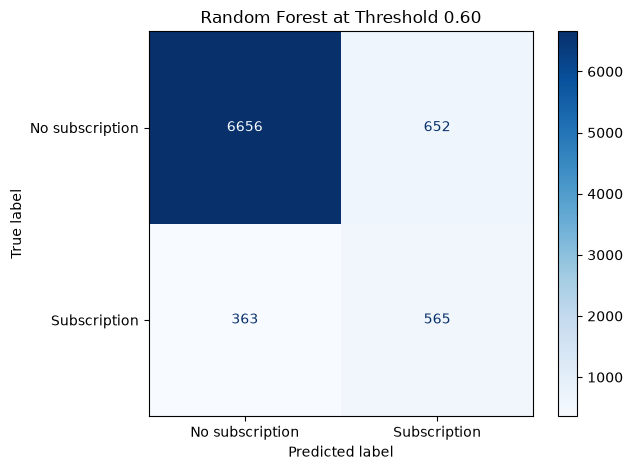

In [23]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    final_pred,
    display_labels=["No subscription", "Subscription"],
    values_format="d",
    cmap="Blues"
)

plt.title("Random Forest at Threshold 0.60")
plt.tight_layout()
plt.show()

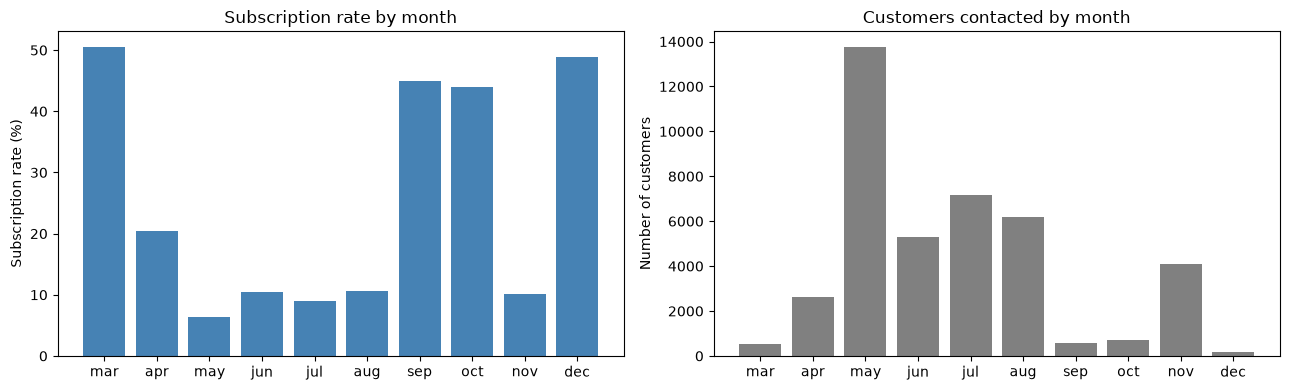

In [24]:
month_order = [
    "jan", "feb", "mar", "apr", "may", "jun",
    "jul", "aug", "sep", "oct", "nov", "dec"
]

monthly = df.groupby("month", observed=False).agg(
    customers=("y", "size"),
    subscription_rate_pct=("y", lambda values: (values == "yes").mean() * 100)
).reindex(month_order).dropna()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].bar(monthly.index, monthly["subscription_rate_pct"], color="steelblue")
axes[0].set_title("Subscription rate by month")
axes[0].set_ylabel("Subscription rate (%)")

axes[1].bar(monthly.index, monthly["customers"], color="gray")
axes[1].set_title("Customers contacted by month")
axes[1].set_ylabel("Number of customers")

plt.tight_layout()
plt.show()

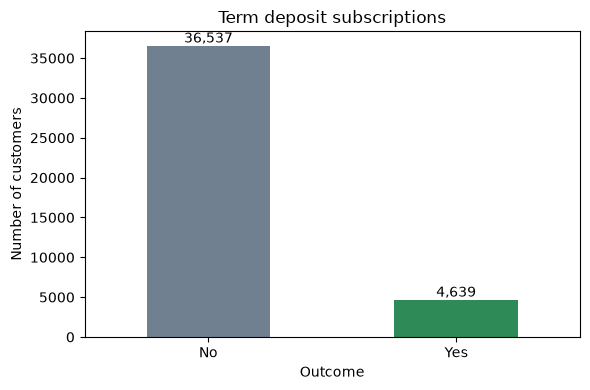

In [25]:
target_counts = df["y"].value_counts().reindex(["no", "yes"])

ax = target_counts.plot(
    kind="bar",
    color=["slategray", "seagreen"],
    figsize=(6, 4)
)
ax.set_title("Term deposit subscriptions")
ax.set_xlabel("Outcome")
ax.set_ylabel("Number of customers")
ax.set_xticklabels(["No", "Yes"], rotation=0)

for bar in ax.patches:
    ax.annotate(
        f"{int(bar.get_height()):,}",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

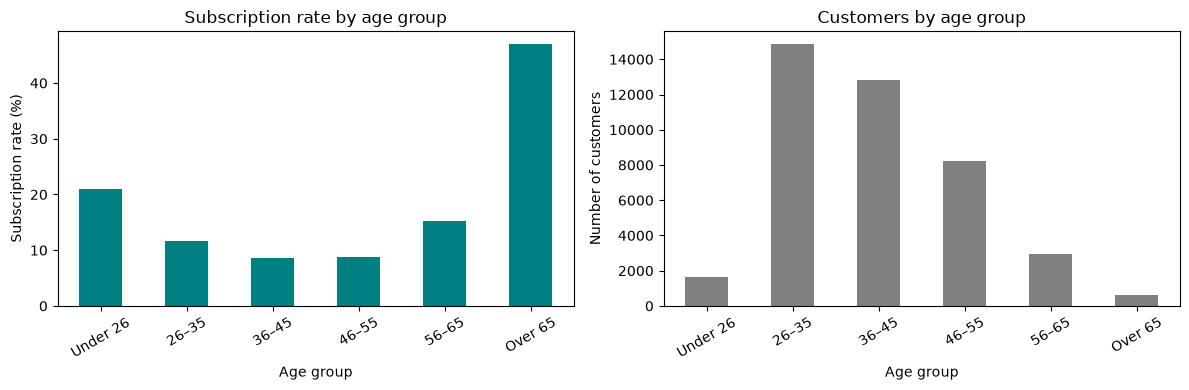

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

age_summary["subscription_rate_pct"].plot(
    kind="bar", ax=axes[0], color="teal"
)
axes[0].set_title("Subscription rate by age group")
axes[0].set_xlabel("Age group")
axes[0].set_ylabel("Subscription rate (%)")
axes[0].tick_params(axis="x", rotation=30)

age_summary["customers"].plot(
    kind="bar", ax=axes[1], color="gray"
)
axes[1].set_title("Customers by age group")
axes[1].set_xlabel("Age group")
axes[1].set_ylabel("Number of customers")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

,customers,subscriptions,subscription_rate_pct
poutcome,,,
failure,4252,605,14.23
nonexistent,35551,3140,8.83
success,1373,894,65.11


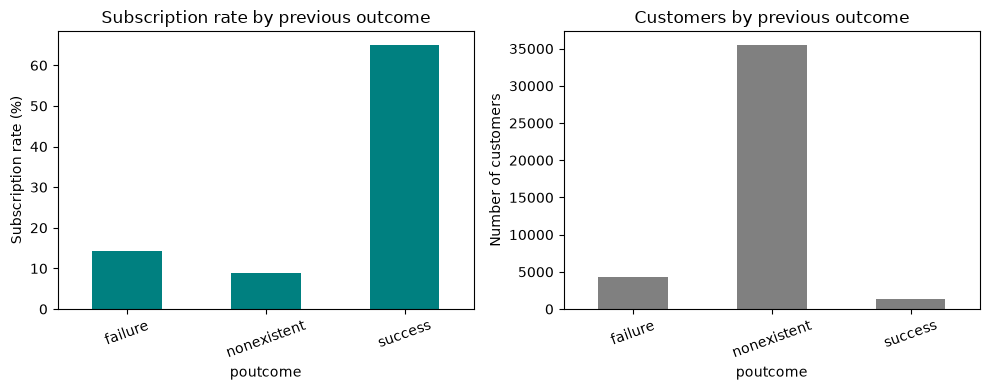

In [27]:
poutcome_summary = df.groupby("poutcome", observed=False).agg(
    customers=("y", "size"),
    subscriptions=("y", lambda values: (values == "yes").sum())
)
poutcome_summary["subscription_rate_pct"] = (
    poutcome_summary["subscriptions"]
    / poutcome_summary["customers"] * 100
).round(2)

display(poutcome_summary)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

poutcome_summary["subscription_rate_pct"].plot(
    kind="bar", ax=axes[0], color="teal"
)
axes[0].set_title("Subscription rate by previous outcome")
axes[0].set_ylabel("Subscription rate (%)")
axes[0].tick_params(axis="x", rotation=20)

poutcome_summary["customers"].plot(
    kind="bar", ax=axes[1], color="gray"
)
axes[1].set_title("Customers by previous outcome")
axes[1].set_ylabel("Number of customers")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

In [28]:
contact_summary = df.groupby("contact", observed=False).agg(
    customers=("y", "size"),
    subscriptions=("y", lambda values: (values == "yes").sum())
)
contact_summary["subscription_rate_pct"] = (
    contact_summary["subscriptions"]
    / contact_summary["customers"] * 100
).round(2)

display(contact_summary)

,customers,subscriptions,subscription_rate_pct
contact,,,
cellular,26135,3852,14.74
telephone,15041,787,5.23


## Model Comparison and Selection

I compared logistic regression, a decision tree, and a random forest. Because only about 11.27% of customers subscribed, I considered precision, recall, and F1 for the “yes” class instead of relying on accuracy alone.

At the default 0.50 threshold, the random forest performed best among the three models in these comparisons. It had an accuracy of 0.860, precision of 0.420, recall of 0.636, F1 score of 0.506, ROC-AUC of 0.813, and average precision of 0.487. The logistic regression and decision tree had lower F1 scores of 0.461 and 0.484, respectively.

I also compared several thresholds for the random forest. Of the thresholds tested, 0.60 gave the highest F1 score (0.527). At this threshold, precision was 0.464 and recall was 0.609. The model flagged 1,217 customers in the test set; 565 subscribed and 652 did not.

The 0.60 threshold is a candidate based on F1, not a final business decision. The bank should choose its operating threshold based on outreach capacity and the costs of missed opportunities and unnecessary contacts. These are development results because the test set was used repeatedly during model comparison and threshold exploration.

## Marketing Recommendations

- **Prioritize customers with a successful previous campaign outcome.** In this dataset, 65.11% of customers whose previous campaign was successful subscribed to a term deposit. The bank could consider giving similar customers higher priority for follow-up outreach.

- **Test cellular outreach.** The subscription rate was 14.74% for customers contacted by cellular phone and 5.23% for customers contacted by telephone. The bank could test outreach by channel while respecting customer preferences and measuring results.

- **Review repeated-contact practices.** The subscription rate declined from 13.04% after one contact to 6.14% for five or more contacts during the campaign. The bank could monitor response rates and avoid unnecessary repeated calls.

- **Use predictions to prioritize, not guarantee, outcomes.** At a 0.60 threshold, the random forest flagged 1,217 customers in the test set. Of these, 565 subscribed and 652 did not. The bank should choose an operating threshold based on its outreach capacity and the costs of missed opportunities and unnecessary contacts.

These findings show associations in this dataset. They do not prove that a particular channel, contact schedule, or customer characteristic causes a subscription.

## Challenges and Limitations

- **Imbalanced target:** About 11.27% of customers subscribed, so a model could achieve high accuracy by predicting “no” for nearly everyone. I compared precision, recall, and F1 for subscribers as well as accuracy.
- **Duplicate records:** I removed 12 exact duplicate rows before splitting the data.
- **Unknown category values:** Several categorical fields contain “unknown.” I retained these as categories rather than deleting those rows.
- **Special code in `pdays`:** The value 999 means the customer was not previously contacted; it is not a literal number of days. This needs careful interpretation when preparing the feature.
- **Potential data leakage:** The brief notes that `duration` is only known after a call. I excluded it from the predictive model so the model uses information available before the call.
- **Older data:** The records come from campaigns conducted around 2008–2010. Customer behavior, communication channels, and economic conditions may differ today, so the model should be retrained and re-evaluated on recent data before practical use.
- **Small groups:** Some months and previous-contact counts have relatively few customers, so their high or low subscription rates may be less stable.
- **Association is not causation:** Feature importance and group subscription rates show patterns in this dataset; they do not prove that a feature or campaign choice causes a subscription.
- **Evaluation limitation:** I used the test set repeatedly to compare models and thresholds. The reported scores are development results and may be optimistic compared with an untouched final evaluation.

## Conclusion

The project compared logistic regression, a decision tree, and a random forest to predict term deposit subscriptions. The random forest performed best among the models compared. At the 0.60 threshold, it achieved a precision of 0.464 and recall of 0.609 on the test set, identifying 565 subscribers among 1,217 flagged records.

The analysis found higher subscription rates among customers with a successful previous campaign outcome and among those contacted by cellular phone. These are patterns in the historical data, not proof of cause. The `duration` feature was excluded because it is only known after a call.

The dataset covers campaigns from 2008–2010, and the test set was used repeatedly during model comparison. The results should therefore be treated as development findings; the model should be checked on recent data before practical use.